In [1]:
# Use of every functions are also mentioned 
import pandas as pd # importing pandas library 
df = pd.read_csv('spending_data.csv') #this upload our file in pandas and read the file 
print('Rows, Columns:', df.shape) #df.shape read the no of rows and columns 
df.head()

Rows, Columns: (255, 11)


,Customer_ID,City,Occupation,Primary_Payment_Mode,Account_Type,Age,Monthly_Income,Monthly_Transactions,Credit_Utilization_Pct,Statement_Date,Savings_Rate_Pct
0,C1042,Pune,Self_Employed,Debit_Card,Current,60.0,38000.0,52,56.2,2025-06-22,12.7
1,C1073,Delhi,Salaried,Credit_Card,Current,29.0,82000.0,38,36.2,2025-03-28,33.0
2,C1066,Bengaluru,Self_Employed,Credit_Card,Salary,48.0,69500.0,48,82.4,2025-02-11,28.3
3,C1145,Pune,Student,Debit_Card,Salary,22.0,19000.0,23,35.1,2025-06-30,24.2
4,C1025,Bengaluru,Salaried,UPI,Salary,50.0,NaN,61,23.5,2026-05-17,10.3


In [2]:
#Taking info abt our data 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             255 non-null    str    
 1   City                    255 non-null    str    
 2   Occupation              250 non-null    str    
 3   Primary_Payment_Mode    255 non-null    str    
 4   Account_Type            255 non-null    str    
 5   Age                     250 non-null    float64
 6   Monthly_Income          249 non-null    float64
 7   Monthly_Transactions    255 non-null    int64  
 8   Credit_Utilization_Pct  250 non-null    float64
 9   Statement_Date          255 non-null    str    
 10  Savings_Rate_Pct        255 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 22.0 KB


NOTE:
From the above command, we got to know that some of the columns have null values.
Therefor before working on out data we need to cleanse it .

In [3]:
#Finding exact missing/duplicate values 
#USING PANDAS 
import pandas as pd 
df = pd.read_csv("spending_data.csv")
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Customer_ID               0
City                      0
Occupation                5
Primary_Payment_Mode      0
Account_Type              0
Age                       5
Monthly_Income            6
Monthly_Transactions      0
Credit_Utilization_Pct    5
Statement_Date            0
Savings_Rate_Pct          0
dtype: int64
Duplicate rows: 5


In [4]:
#CLeansing our data
import pandas as pd
df = pd.read_csv("spending_data.csv")#df is 2D data structure provide by pandas that stores data in rows and columns.
print("rows before cleansing:", len(df))

df=df.drop_duplicates()#reassigned to df so changes can be saved 
df["City"]=df["City"].str.lower()
df["City"]=df["City"].str.strip()#removes unnecessary spaces from start to end 
for col in ["City","Occupation","Primary_Payment_Mode","Account_Type"]:
    print(df[col].value_counts())
print('Rows after cleaning:', len(df), '| Missing values left:', df.isna().sum().sum())    

rows before cleansing: 255
City
delhi        82
mumbai       67
bengaluru    46
pune         41
kolkata      14
Name: count, dtype: int64
Occupation
Salaried         109
Student           51
Self_Employed     46
Freelancer        40
Name: count, dtype: int64
Primary_Payment_Mode
UPI            126
Debit_Card      60
Credit_Card     40
Cash            24
Name: count, dtype: int64
Account_Type
Savings    137
Salary      85
Current     28
Name: count, dtype: int64
Rows after cleaning: 250 | Missing values left: 20


In [5]:
df.isnull().sum()

Customer_ID               0
City                      0
Occupation                4
Primary_Payment_Mode      0
Account_Type              0
Age                       5
Monthly_Income            6
Monthly_Transactions      0
Credit_Utilization_Pct    5
Statement_Date            0
Savings_Rate_Pct          0
dtype: int64

In [6]:
df["Occupation"].mode()[0]

'Salaried'

In [7]:
df["Occupation"]=df["Occupation"].fillna(df["Occupation"].mode()[0]) #fillna-fills the missing values 
df["Occupation"].isnull().sum()

np.int64(0)

In [8]:
#for numerical missing values we'll use median 
df["Age"].median()
df["Age"]=df["Age"].fillna(df["Age"].median())
df["Age"].isnull().sum()

np.int64(0)

In [9]:
#better option 
numeric_col=["Age","Monthly_Income","Credit_Utilization_Pct"]
for col in numeric_col:
    df[col]=df[col].fillna(df[col].median())
df.isnull().sum()    

Customer_ID               0
City                      0
Occupation                0
Primary_Payment_Mode      0
Account_Type              0
Age                       0
Monthly_Income            0
Monthly_Transactions      0
Credit_Utilization_Pct    0
Statement_Date            0
Savings_Rate_Pct          0
dtype: int64

In [10]:
import pandas as pd 
df.info()


<class 'pandas.DataFrame'>
Index: 250 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             250 non-null    str    
 1   City                    250 non-null    str    
 2   Occupation              250 non-null    str    
 3   Primary_Payment_Mode    250 non-null    str    
 4   Account_Type            250 non-null    str    
 5   Age                     250 non-null    float64
 6   Monthly_Income          250 non-null    float64
 7   Monthly_Transactions    250 non-null    int64  
 8   Credit_Utilization_Pct  250 non-null    float64
 9   Statement_Date          250 non-null    str    
 10  Savings_Rate_Pct        250 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 23.4 KB


In [11]:
#Saving cleansed file 
import pandas as pd 
df.to_csv("cleansed_spending_data.csv",index=False)

In [12]:
#Adding columns 
#Income_per_Transaction
df=pd.read_csv("cleansed_spending_data.csv")
df["Income_per_Transaction"]=df["Monthly_Income"]/df["Monthly_Transactions"]
#Saver_Status
df["Saver_Status"]=df["Savings_Rate_Pct"].apply( lambda x : "Lower Saver" if x<10 else "Moderate" if x<=25 else "Strong")
df["Age_Band"]=pd.cut(
    df["Age"],
    bins=[17,25,35,45,float("inf")],
    labels=["18-25","26-35","36-45","46+"]

)
df[["Income_per_Transaction","Saver_Status","Age_Band"]].head()

,Income_per_Transaction,Saver_Status,Age_Band
0,730.769231,Moderate,46+
1,2157.894737,Strong,26-35
2,1447.916667,Strong,46+
3,826.086957,Moderate,18-25
4,754.098361,Moderate,46+


In [13]:
df.to_csv("cleansed_spending_data.csv",index=False)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Customer_ID             250 non-null    str     
 1   City                    250 non-null    str     
 2   Occupation              250 non-null    str     
 3   Primary_Payment_Mode    250 non-null    str     
 4   Account_Type            250 non-null    str     
 5   Age                     250 non-null    float64 
 6   Monthly_Income          250 non-null    float64 
 7   Monthly_Transactions    250 non-null    int64   
 8   Credit_Utilization_Pct  250 non-null    float64 
 9   Statement_Date          250 non-null    str     
 10  Savings_Rate_Pct        250 non-null    float64 
 11  Income_per_Transaction  250 non-null    float64 
 12  Saver_Status            250 non-null    str     
 13  Age_Band                250 non-null    category
dtypes: category(1), float64(5), int64(1),

Q1. WHat does Saving_Rate_Pct look like overall?
We need to understand:
1. centre: Mean and median 
2. spread: Standard Deviation and range 
3. Shapes:DIstribution of saving rates
4. Extremes: MInimum and Maximum values and outliners 

In [15]:
df["Savings_Rate_Pct"].describe()

count    250.000000
mean      22.159200
std       10.208419
min        1.000000
25%       15.300000
50%       22.500000
75%       28.675000
max       49.500000
Name: Savings_Rate_Pct, dtype: float64

In [16]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

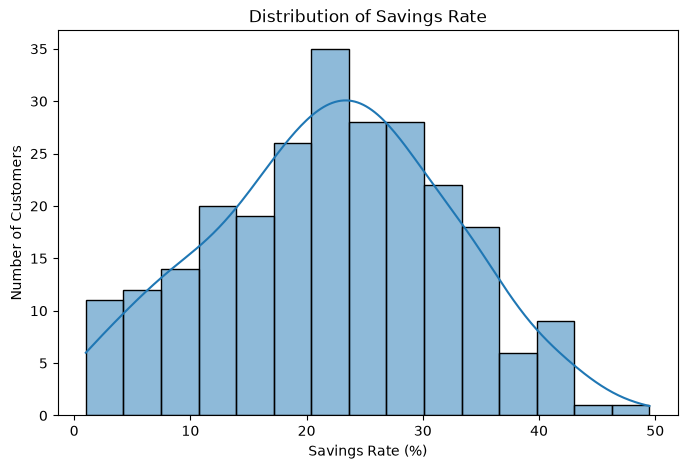

In [18]:
import matplotlib.pyplot as plt 
import seaborn as sns 
import pandas as pd
plt.figure(figsize=(8,5))
sns.histplot(df["Savings_Rate_Pct"],
bins=15, kde=True)
plt.title("Distribution of Savings Rate")
plt.xlabel("Savings Rate (%)")
plt.ylabel("Number of Customers")
plt.show()

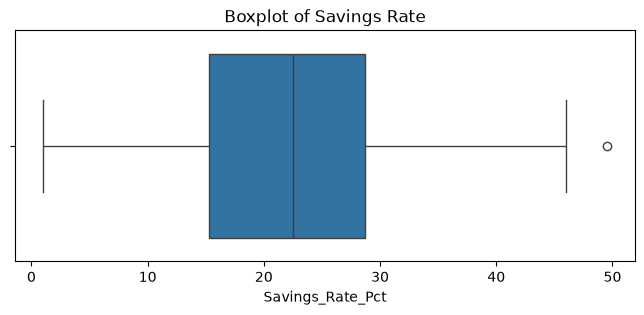

In [19]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df["Savings_Rate_Pct"])
plt.title("Boxplot of Savings Rate")
plt.show()

Q2. Realtionship Analysis 
Our objective: Find out how savings rate is related to income, transactions, age and credit utilisation.

In [20]:
cols = [
    "Monthly_Income",
    "Monthly_Transactions",
    "Age",
    "Credit_Utilization_Pct",
    "Savings_Rate_Pct"
]

correlation = df[cols].corr()

print(correlation["Savings_Rate_Pct"])

Monthly_Income            0.538093
Monthly_Transactions     -0.573484
Age                       0.255098
Credit_Utilization_Pct   -0.043139
Savings_Rate_Pct          1.000000
Name: Savings_Rate_Pct, dtype: float64


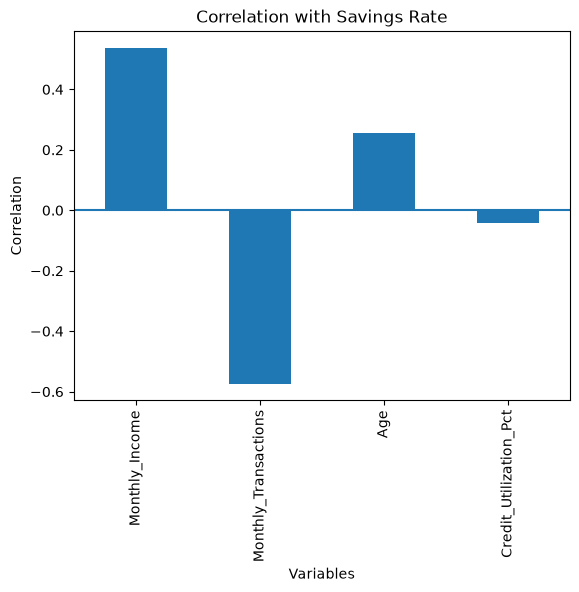

In [25]:
correlation["Savings_Rate_Pct"].drop("Savings_Rate_Pct").plot(kind="bar")
plt.title("Correlation with Savings Rate")
plt.xlabel("Variables")
plt.ylabel("Correlation")
plt.axhline(0)
plt.show()

Q3.Compare savings rates across categories
We need to compare the avg Savings_Rate_Pct across:
1. Occupation
2. City
3. Primary_Payment_Mode
4. Account_Type 

In [29]:
df.groupby("Occupation")["Savings_Rate_Pct"].mean()


Occupation
Freelancer       20.370000
Salaried         25.855752
Self_Employed    24.745652
Student          13.039216
Name: Savings_Rate_Pct, dtype: float64

In [30]:
df.groupby("City")["Savings_Rate_Pct"].mean()

City
bengaluru    21.673913
delhi        22.646341
kolkata      19.557143
mumbai       22.382090
pune         22.253659
Name: Savings_Rate_Pct, dtype: float64

In [31]:
df.groupby("Primary_Payment_Mode")["Savings_Rate_Pct"].mean()

Primary_Payment_Mode
Cash           26.645833
Credit_Card    26.422500
Debit_Card     22.985000
UPI            19.557937
Name: Savings_Rate_Pct, dtype: float64

In [33]:
df.groupby("Account_Type")["Savings_Rate_Pct"].mean()

Account_Type
Current    20.221429
Salary     22.629412
Savings    22.263504
Name: Savings_Rate_Pct, dtype: float64

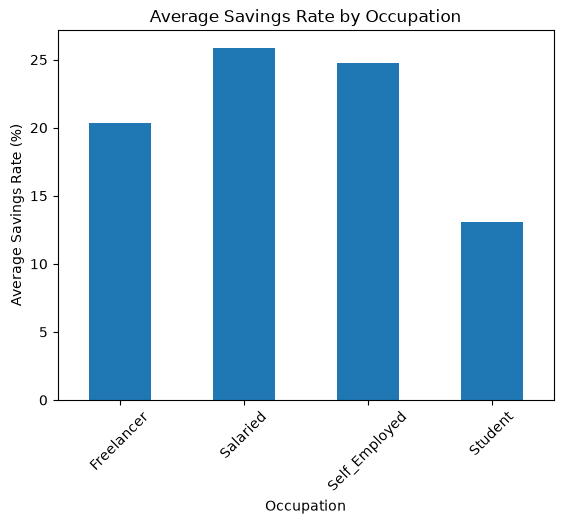

In [34]:
df.groupby("Occupation")["Savings_Rate_Pct"].mean().plot(kind="bar")

plt.title("Average Savings Rate by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Savings Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [35]:
low_savers = df[df["Savings_Rate_Pct"]<10]
low_savers

,Customer_ID,City,Occupation,Primary_Payment_Mode,Account_Type,Age,Monthly_Income,Monthly_Transactions,Credit_Utilization_Pct,Statement_Date,Savings_Rate_Pct,Income_per_Transaction,Saver_Status,Age_Band
10,C1231,bengaluru,Student,Cash,Savings,23.0,10500.0,37,37.4,2025-07-28,6.4,283.783784,Lower Saver,18-25
18,C1249,bengaluru,Student,Debit_Card,Savings,21.0,9500.0,38,28.6,2026-08-06,5.1,250.000000,Lower Saver,18-25
27,C1245,delhi,Freelancer,UPI,Salary,43.0,20000.0,29,11.8,2025-08-12,7.9,689.655172,Lower Saver,36-45
39,C1204,delhi,Student,UPI,Salary,18.0,10500.0,68,57.4,2025-02-21,3.0,154.411765,Lower Saver,18-25
41,C1041,kolkata,Freelancer,UPI,Salary,40.0,19000.0,34,39.5,2026-10-15,4.4,558.823529,Lower Saver,36-45
44,C1185,mumbai,Student,UPI,Savings,23.0,10500.0,35,45.4,2025-01-14,6.9,300.000000,Lower Saver,18-25
50,C1033,pune,Student,UPI,Current,18.0,14500.0,52,49.3,2025-12-11,1.8,278.846154,Lower Saver,18-25
57,C1125,bengaluru,Freelancer,UPI,Savings,55.0,24500.0,39,35.9,2026-03-29,4.6,628.205128,Lower Saver,46+
63,C1173,kolkata,Freelancer,UPI,Savings,43.0,33500.0,56,13.9,2026-09-24,7.7,598.214286,Lower Saver,36-45
69,C1201,mumbai,Salaried,UPI,Savings,52.0,56500.0,48,23.7,2026-03-11,9.6,1177.083333,Lower Saver,46+


In [36]:
print("Number of Low Savers:", len(low_savers))

Number of Low Savers: 34


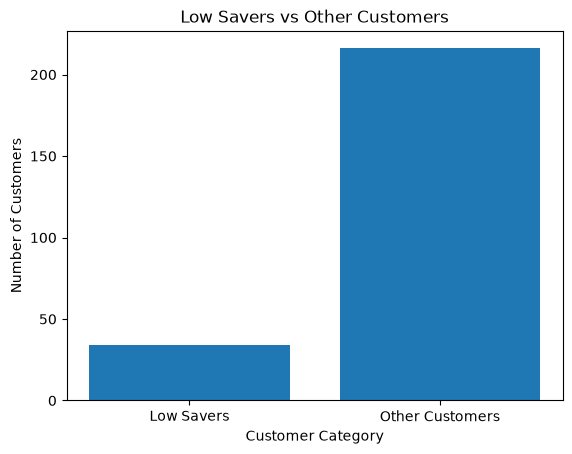

In [37]:
saver_counts = [
    len(low_savers),
    len(df) - len(low_savers)
]

plt.bar(["Low Savers", "Other Customers"], saver_counts)

plt.title("Low Savers vs Other Customers")
plt.xlabel("Customer Category")
plt.ylabel("Number of Customers")
plt.show()

In [38]:
df.to_csv("cleansed_spending_data.csv", index=False)

KEY INSIGHTS 

In [39]:
print("========== KEY INSIGHTS ==========")

# 1. Total number of customers
print("Total Customers:", len(df))

# 2. Average savings rate
print("Average Savings Rate:", round(df["Savings_Rate_Pct"].mean(), 2), "%")

# 3. Highest saving occupation
occupation = df.groupby("Occupation")["Savings_Rate_Pct"].mean()
print("Highest Saving Occupation:", occupation.idxmax())

# 4. City with highest savings rate
city = df.groupby("City")["Savings_Rate_Pct"].mean()
print("City with Highest Savings Rate:", city.idxmax())

# 5. Most common payment mode
print("Most Common Payment Mode:", df["Primary_Payment_Mode"].mode()[0])

# 6. Low Saver count
print("Number of Low Savers:", len(low_savers))

# 7. Percentage of Low Savers
percentage = (len(low_savers) / len(df)) * 100
print("Low Saver Percentage:", round(percentage, 2), "%")

print("==================================")

========== KEY INSIGHTS ==========
Total Customers: 250
Average Savings Rate: 22.16 %
Highest Saving Occupation: Salaried
City with Highest Savings Rate: delhi
Most Common Payment Mode: UPI
Number of Low Savers: 34
Low Saver Percentage: 13.6 %
